In [1]:
# ============================================================
# 1. GPU SETUP + CONFIGURATION — RUN FIRST
# ============================================================
# CUDA_VISIBLE_DEVICES must be set BEFORE importing TensorFlow.
import os
GPU_ID = "3"  # Physical DGX GPU 3 was available in the latest nvidia-smi output.
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

# -------------------------
# Dataset and training config
# -------------------------
ROOT_DIR = Path("/raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED")
OUTPUT_DIR = Path("/raid/home/dgx1725/attention_unet_warwick_outputs")

IMG_SIZE = (256, 384)      # (height, width); approximates GlaS landscape aspect ratio
BATCH_SIZE = 1             # conservative for a shared DGX GPU
EPOCHS = 50
SEED = 42
LEARNING_RATE = 1e-4
PRED_THRESHOLD = 0.5
BOUNDARY_TOLERANCE = 2

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not ROOT_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {ROOT_DIR}\n"
        "ROOT_DIR must contain train/img, train/mask, val/img, val/mask, "
        "test/img, and test/mask. If your folder is named "
        "Warwick_QU_Dataset_Binary_FIXED, update ROOT_DIR to that exact path."
    )

for split in ("train", "val", "test"):
    for subfolder in ("img", "mask"):
        folder = ROOT_DIR / split / subfolder
        if not folder.is_dir():
            raise FileNotFoundError(f"Required folder not found: {folder}")

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

# Configure memory growth before TensorFlow initializes GPU memory.
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError(
        "TensorFlow cannot detect a GPU. Check the DGX environment and "
        "CUDA_VISIBLE_DEVICES, then restart the kernel and run this cell first."
    )
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print(f"Could not set memory growth for {gpu}: {exc}")

print("TensorFlow version:", tf.__version__)
print("Visible logical GPUs:", tf.config.list_logical_devices("GPU"))
print("Dataset root:", ROOT_DIR)
print("Output directory:", OUTPUT_DIR)

with tf.device("/GPU:0"):
    _gpu_test = tf.matmul(tf.random.normal((64, 64)), tf.random.normal((64, 64)))
print("GPU matrix test:", _gpu_test.shape, _gpu_test.device)
del _gpu_test

2026-10-20 03:00:48.551567: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 03:00:48.551611: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 03:00:48.553064: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow version: 2.15.1
Visible logical GPUs: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]
Dataset root: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED
Output directory: /raid/home/dgx1725/attention_unet_warwick_outputs
GPU matrix test: (64, 64) /job:localhost/replica:0/task:0/device:GPU:0


In [2]:
# ============================================================
# 2. PAIR IMAGES WITH MASKS IN EACH PROVIDED SPLIT
# ============================================================
VALID_EXTS = {".png", ".bmp", ".bm", ".jpg", ".jpeg", ".tif", ".tiff"}


def list_image_files(folder):
    """List supported images in one folder (not recursively)."""
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTS
    )


def image_key(path):
    """Normalize an image filename to its case-insensitive stem."""
    return path.stem.lower()


def mask_key(path):
    """Normalize a mask stem, removing the dataset's trailing '_anno'."""
    key = path.stem.lower()
    if key.endswith("_anno"):
        key = key[:-len("_anno")]
    return key


def get_pairs(split):
    """Return (image_path, mask_path) pairs for train/val/test."""
    img_dir = ROOT_DIR / split / "img"
    mask_dir = ROOT_DIR / split / "mask"
    if not img_dir.is_dir() or not mask_dir.is_dir():
        raise FileNotFoundError(f"Expected folders: {img_dir} and {mask_dir}")

    image_files = list_image_files(img_dir)
    mask_files = list_image_files(mask_dir)
    if not image_files:
        raise ValueError(f"No supported images found in {img_dir}")
    if not mask_files:
        raise ValueError(f"No supported masks found in {mask_dir}")

    mask_map = {}
    duplicate_mask_keys = []
    for mask_path in mask_files:
        key = mask_key(mask_path)
        if key in mask_map:
            duplicate_mask_keys.append(key)
        else:
            mask_map[key] = mask_path
    if duplicate_mask_keys:
        raise ValueError(
            f"Duplicate mask filename keys in {mask_dir}: "
            f"{sorted(set(duplicate_mask_keys))[:10]}"
        )

    pairs = []
    missing_masks = []
    used_mask_paths = set()
    seen_image_keys = set()
    for image_path in image_files:
        key = image_key(image_path)
        if key in seen_image_keys:
            raise ValueError(f"Duplicate image filename key in {img_dir}: {key}")
        seen_image_keys.add(key)
        mask_path = mask_map.get(key)
        if mask_path is None:
            missing_masks.append(image_path.name)
        else:
            pairs.append((str(image_path), str(mask_path)))
            used_mask_paths.add(mask_path)

    extra_masks = [p.name for p in mask_files if p not in used_mask_paths]
    if missing_masks or extra_masks:
        details = [f"Pairing failed in split '{split}'."]
        if missing_masks:
            details.append(f"Images without masks ({len(missing_masks)}): {missing_masks[:15]}")
        if extra_masks:
            details.append(f"Masks without images ({len(extra_masks)}): {extra_masks[:15]}")
        details.append(
            "Check that image 'name.png' has a mask named 'name_anno.png' "
            "or 'name.png' in the same split."
        )
        raise ValueError("\n".join(details))

    if len(pairs) != len(image_files):
        raise RuntimeError(f"Internal pairing count mismatch for split {split}")

    print(
        f"{split:>5}: {len(image_files)} images, {len(mask_files)} masks, "
        f"{len(pairs)} matched pairs"
    )
    return pairs


train_pairs = get_pairs("train")
val_pairs = get_pairs("val")
test_pairs = get_pairs("test")

# Check that image IDs do not overlap across splits.
def split_ids(pairs):
    return {Path(img_path).stem.lower() for img_path, _ in pairs}

train_ids, val_ids, test_ids = map(split_ids, (train_pairs, val_pairs, test_pairs))
if train_ids & val_ids or train_ids & test_ids or val_ids & test_ids:
    print("WARNING: identical image filenames appear in more than one split.")
    print("train/val overlap:", sorted(train_ids & val_ids)[:10])
    print("train/test overlap:", sorted(train_ids & test_ids)[:10])
    print("val/test overlap:", sorted(val_ids & test_ids)[:10])
else:
    print("Filename-level split overlap check: no overlapping image IDs detected.")

print("\nExample pairs:")
for image_path, mask_path in (train_pairs[:3] + val_pairs[:1] + test_pairs[:1]):
    print(f"  {Path(image_path).name}  <->  {Path(mask_path).name}")

# Inspect a few source masks before training. They should represent background
# as 0 and foreground as a positive value (often 255).
print("\nSample grayscale mask pixel values:")
for _, mask_path in train_pairs[:3]:
    raw_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if raw_mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    print(Path(mask_path).name, "shape=", raw_mask.shape,
          "unique values (first 20)=", np.unique(raw_mask)[:20])

train: 133 images, 133 masks, 133 matched pairs
  val: 16 images, 16 masks, 16 matched pairs
 test: 16 images, 16 masks, 16 matched pairs
Filename-level split overlap check: no overlapping image IDs detected.

Example pairs:
  testA_17.png  <->  testA_17_anno.png
  testA_18.png  <->  testA_18_anno.png
  testA_19.png  <->  testA_19_anno.png
  testA_1.png  <->  testA_1_anno.png
  testB_1.png  <->  testB_1_anno.png

Sample grayscale mask pixel values:
testA_17_anno.png shape= (522, 775) unique values (first 20)= [  0 255]
testA_18_anno.png shape= (522, 775) unique values (first 20)= [  0 255]
testA_19_anno.png shape= (522, 775) unique values (first 20)= [  0 255]



Dataset batches:
train: 133
val:   16
test:  16

Loaded image shape: (256, 384, 3) range: 0.01568627543747425 1.0
Loaded mask shape: (256, 384, 1) unique values: [0. 1.]
Foreground fraction: 0.6021220088005066


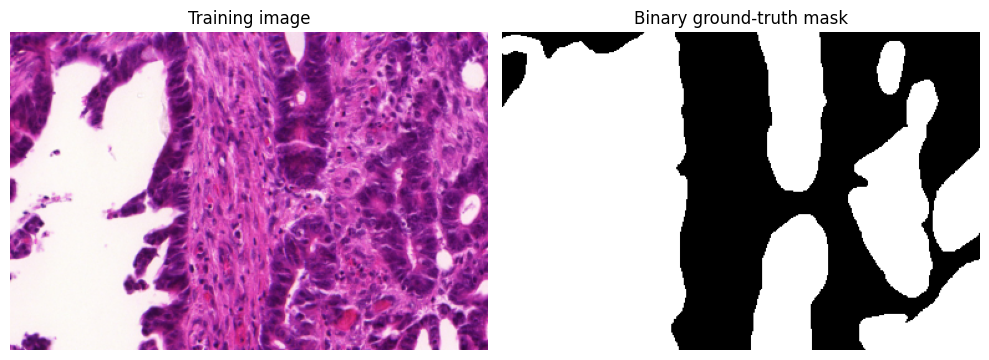

In [3]:
# ============================================================
# 3. IMAGE/MASK LOADING, BINARIZATION, AUGMENTATION, TF.DATA
# ============================================================

def decode_path(path_value):
    """Decode paths passed through tf.numpy_function."""
    if isinstance(path_value, np.ndarray):
        path_value = path_value.item()
    if isinstance(path_value, (bytes, np.bytes_)):
        return path_value.decode("utf-8")
    return str(path_value)


def load_image_mask(img_path, mask_path):
    """Load a color image and its binary mask, resized to IMG_SIZE."""
    img_path = decode_path(img_path)
    mask_path = decode_path(mask_path)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA
    )
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(
        mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST
    )

    # Dataset has binary masks: background=0, any positive value=foreground.
    # Output values are exactly 0.0 and 1.0 for sigmoid/BCE training.
    mask = (mask > 0).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)
    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    """Shape-safe, synchronized augmentation for the rectangular 256x384 inputs."""
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    # Do not use 90-degree rotations here: H and W differ, so rot90 swaps shapes.
    return image, mask


def make_dataset(pairs, training=False):
    if not pairs:
        raise ValueError("Cannot build a dataset from zero image-mask pairs.")
    image_paths = [p[0] for p in pairs]
    mask_paths = [p[1] for p in pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(pairs), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE, drop_remainder=False)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset


train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
test_ds = make_dataset(test_pairs, training=False)

print("\nDataset batches:")
print("train:", tf.data.experimental.cardinality(train_ds).numpy())
print("val:  ", tf.data.experimental.cardinality(val_ds).numpy())
print("test: ", tf.data.experimental.cardinality(test_ds).numpy())

# Visual sanity check: first pair from training split.
check_image, check_mask = load_image_mask(*train_pairs[0])
print("\nLoaded image shape:", check_image.shape, "range:",
      float(check_image.min()), float(check_image.max()))
print("Loaded mask shape:", check_mask.shape, "unique values:", np.unique(check_mask))
print("Foreground fraction:", float(check_mask.mean()))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(check_image)
plt.title("Training image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(check_mask.squeeze(), cmap="gray", vmin=0, vmax=1)
plt.title("Binary ground-truth mask")
plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# ============================================================
# 4. METRICS, LOSS, AND BASELINE U-NET ARCHITECTURE
# ============================================================
@tf.keras.utils.register_keras_serializable(package="WarwickUNet")
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


@tf.keras.utils.register_keras_serializable(package="WarwickUNet")
def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


@tf.keras.utils.register_keras_serializable(package="WarwickUNet")
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


@tf.keras.utils.register_keras_serializable(package="WarwickUNet")
def bce_dice_loss(y_true, y_pred):
    """Equal-weight binary cross-entropy and soft Dice loss."""
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return 0.5 * bce + 0.5 * dice_loss(y_true, y_pred)


def conv_block(x, filters, name):
    """Two 3x3 Conv-BN-ReLU layers, used in the baseline Attention U-Net."""
    x = layers.Conv2D(
        filters, 3, padding="same", kernel_initializer="he_normal",
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", kernel_initializer="he_normal",
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)
    return x


def attention_gate(skip_tensor, gating_tensor, inter_channels, name):
    """Attention gate that filters encoder skip features using decoder context.

    skip_tensor: encoder feature map x_l (spatial size matches gating_tensor)
    gating_tensor: decoder feature map g
    inter_channels: hidden width for the additive attention calculation
    """
    theta_x = layers.Conv2D(
        inter_channels, kernel_size=1, strides=1, padding="same",
        use_bias=True, kernel_initializer="he_normal", name=f"{name}_theta_x"
    )(skip_tensor)
    phi_g = layers.Conv2D(
        inter_channels, kernel_size=1, strides=1, padding="same",
        use_bias=True, kernel_initializer="he_normal", name=f"{name}_phi_g"
    )(gating_tensor)

    combined = layers.Add(name=f"{name}_add")([theta_x, phi_g])
    combined = layers.Activation("relu", name=f"{name}_relu")(combined)
    attention_coeff = layers.Conv2D(
        1, kernel_size=1, strides=1, padding="same", activation="sigmoid",
        kernel_initializer="glorot_uniform", name=f"{name}_coefficient"
    )(combined)
    gated_skip = layers.Multiply(name=f"{name}_gated_skip")(
        [skip_tensor, attention_coeff]
    )
    return gated_skip


def build_attention_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)):
    """Build baseline Attention U-Net with additive attention gates on skips.

    Standard channel schedule: encoder 64/128/256/512, bottleneck 1024,
    decoder 512/256/128/64. Attention gates filter each encoder skip with
    context from the corresponding upsampled decoder feature map.
    """
    inputs = layers.Input(shape=input_shape, name="input_image")
    encoder_filters = [64, 128, 256, 512]
    skips = []
    x = inputs

    # Encoder
    for level, filters in enumerate(encoder_filters, start=1):
        skip = conv_block(x, filters, name=f"encoder{level}")
        skips.append(skip)
        x = layers.MaxPooling2D((2, 2), name=f"encoder{level}_pool")(skip)

    # Bottom of the U
    x = conv_block(x, 1024, name="bottleneck")

    # Decoder: upsample, gate the matching encoder skip, concatenate, convolve.
    decoder_filters = [512, 256, 128, 64]
    for index, (skip, filters) in enumerate(
        zip(reversed(skips), decoder_filters), start=1
    ):
        x = layers.Conv2DTranspose(
            filters, kernel_size=2, strides=2, padding="same",
            name=f"decoder{index}_upsample"
        )(x)
        gated_skip = attention_gate(
            skip_tensor=skip,
            gating_tensor=x,
            inter_channels=max(filters // 2, 1),
            name=f"attention_gate{index}"
        )
        x = layers.Concatenate(name=f"decoder{index}_concat")([x, gated_skip])
        x = conv_block(x, filters, name=f"decoder{index}")

    outputs = layers.Conv2D(
        1, kernel_size=1, activation="sigmoid", name="binary_mask"
    )(x)
    return Model(inputs=inputs, outputs=outputs, name="Warwick_Baseline_Attention_UNet")


model = build_attention_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=bce_dice_loss,
    metrics=["binary_accuracy", dice_coef, iou_coef],
)
model.summary()

Model: "Warwick_Baseline_Attention_UNet"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_image (InputLayer)    [(None, 256, 384, 3)]        0         []                            
                                                                                                  
 encoder1_conv1 (Conv2D)     (None, 256, 384, 64)         1792      ['input_image[0][0]']         
                                                                                                  
 encoder1_bn1 (BatchNormali  (None, 256, 384, 64)         256       ['encoder1_conv1[0][0]']      
 zation)                                                                                          
                                                                                                  
 encoder1_relu1 (Activation  (None, 256, 384, 64)         0         

In [5]:
# ============================================================
# 5. CALLBACKS AND TRAINING
# ============================================================
best_model_path = OUTPUT_DIR / "best_attention_unet.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-7,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(str(OUTPUT_DIR / "training_log.csv")),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

# EarlyStopping restores the best validation weights.
print("\nTraining complete. Best model checkpoint:", best_model_path)
print("Best validation Dice:", max(history.history.get("val_dice_coef", [float("nan")])) )

Epoch 1/50


I0000 00:00:1792445498.030974   54403 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/133 [============================>.] - ETA: 0s - loss: 0.4439 - binary_accuracy: 0.7331 - dice_coef: 0.6617 - iou_coef: 0.5075
Epoch 1: val_dice_coef improved from -inf to 0.62280, saving model to /raid/home/dgx1725/attention_unet_warwick_outputs/best_attention_unet.keras
133/133 [==============================] - 36s 66ms/step - loss: 0.4429 - binary_accuracy: 0.7339 - dice_coef: 0.6625 - iou_coef: 0.5084 - val_loss: 1.1428 - val_binary_accuracy: 0.4845 - val_dice_coef: 0.6228 - val_iou_coef: 0.4786 - lr: 1.0000e-04
Epoch 2/50
132/133 [============================>.] - ETA: 0s - loss: 0.3626 - binary_accuracy: 0.8011 - dice_coef: 0.7335 - iou_coef: 0.5896
Epoch 2: val_dice_coef improved from 0.62280 to 0.64437, saving model to /raid/home/dgx1725/attention_unet_warwick_outputs/best_attention_unet.keras
133/133 [==============================] - 8s 61ms/step - loss: 0.3611 - binary_accuracy: 0.8020 - dice_coef: 0.7346 - iou_coef: 0.5910 - val_loss: 0.4811 - val_binary_accuracy: 0.70

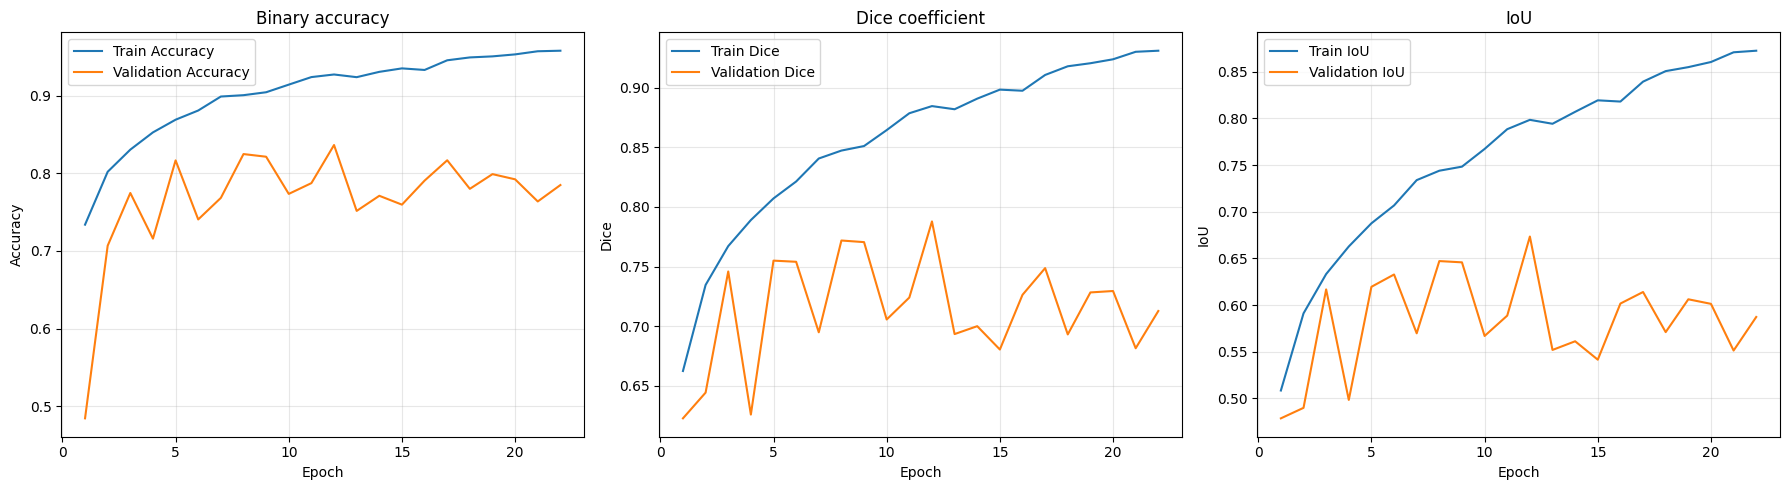

Saved: /raid/home/dgx1725/attention_unet_warwick_outputs/training_curves.png


In [6]:
# ============================================================
# 6. PLOT AND SAVE TRAINING CURVES
# ============================================================
hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
curve_specs = [
    ("binary_accuracy", "val_binary_accuracy", "Binary accuracy", "Accuracy"),
    ("dice_coef", "val_dice_coef", "Dice coefficient", "Dice"),
    ("iou_coef", "val_iou_coef", "IoU", "IoU"),
]
for ax, (train_key, val_key, title, ylabel) in zip(axes, curve_specs):
    ax.plot(epochs_range, hist[train_key], label=f"Train {ylabel}")
    ax.plot(epochs_range, hist[val_key], label=f"Validation {ylabel}")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
curve_path = OUTPUT_DIR / "training_curves.png"
plt.savefig(curve_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)

Test   1/16 | testB_1.png              Dice=0.5956  IoU=0.4241
Test   2/16 | testB_10.png             Dice=0.7973  IoU=0.6630
Test   3/16 | testB_11.png             Dice=0.9701  IoU=0.9419
Test   4/16 | testB_12.png             Dice=0.9178  IoU=0.8482
Test   5/16 | testB_13.png             Dice=0.8928  IoU=0.8063
Test   6/16 | testB_14.png             Dice=0.7089  IoU=0.5490
Test   7/16 | testB_15.png             Dice=0.8787  IoU=0.7837
Test   8/16 | testB_16.png             Dice=0.7913  IoU=0.6547
Test   9/16 | testB_2.png              Dice=0.8860  IoU=0.7953
Test  10/16 | testB_3.png              Dice=0.9734  IoU=0.9482
Test  11/16 | testB_4.png              Dice=0.9445  IoU=0.8949
Test  12/16 | testB_5.png              Dice=0.8443  IoU=0.7306
Test  13/16 | testB_6.png              Dice=0.6155  IoU=0.4446
Test  14/16 | testB_7.png              Dice=0.9396  IoU=0.8860
Test  15/16 | testB_8.png              Dice=0.9274  IoU=0.8646
Test  16/16 | testB_9.png              Dice=0.7303  IoU

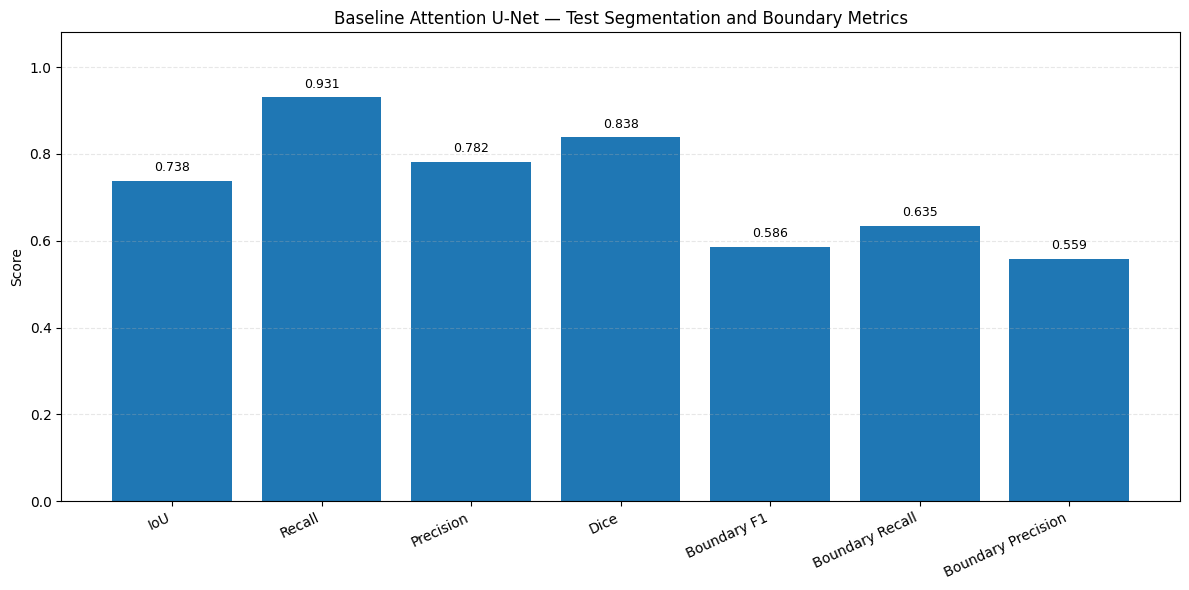

Saved test metric graph: /raid/home/dgx1725/attention_unet_warwick_outputs/test_metrics_graph.png


In [7]:
# ============================================================
# 7. FINAL TEST-SET EVALUATION (TEST NOT USED FOR MODEL SELECTION)
# ============================================================
def extract_binary_boundary(binary_mask):
    mask = (np.asarray(binary_mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(
        mask, np.ones((3, 3), dtype=np.uint8), iterations=1,
        borderType=cv2.BORDER_CONSTANT, borderValue=0
    )
    return (mask - eroded).astype(np.uint8)


def segmentation_scores(gt_mask, pred_mask, tolerance=2):
    gt = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Mask shape mismatch: GT {gt.shape}, prediction {pred.shape}")

    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))

    precision = tp / (tp + fp) if tp + fp else (1.0 if tp + fn == 0 else 0.0)
    recall = tp / (tp + fn) if tp + fn else (1.0 if tp + fp == 0 else 0.0)
    dice_den = 2 * tp + fp + fn
    dice = 2 * tp / dice_den if dice_den else 1.0
    iou_den = tp + fp + fn
    iou = tp / iou_den if iou_den else 1.0

    gt_boundary = extract_binary_boundary(gt)
    pred_boundary = extract_binary_boundary(pred)
    tol = max(0, int(tolerance))
    kernel_size = 2 * tol + 1
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (kernel_size, kernel_size)
    )
    gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
    pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)

    matched_pred = int(np.sum((pred_boundary > 0) & (gt_dilated > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (pred_dilated > 0)))
    n_pred_boundary = int(np.sum(pred_boundary))
    n_gt_boundary = int(np.sum(gt_boundary))

    boundary_precision = (
        matched_pred / n_pred_boundary if n_pred_boundary else
        (1.0 if n_gt_boundary == 0 else 0.0)
    )
    boundary_recall = (
        matched_gt / n_gt_boundary if n_gt_boundary else
        (1.0 if n_pred_boundary == 0 else 0.0)
    )
    bp_br_sum = boundary_precision + boundary_recall
    boundary_f1 = (2 * boundary_precision * boundary_recall / bp_br_sum) if bp_br_sum else 0.0

    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }


METRICS = [
    "iou", "recall", "precision", "dice",
    "boundary_f1", "boundary_recall", "boundary_precision"
]
DISPLAY_NAMES = [
    "IoU", "Recall", "Precision", "Dice",
    "Boundary F1", "Boundary Recall", "Boundary Precision"
]

if not test_pairs:
    raise ValueError("test split is empty; cannot evaluate final test metrics")

rows = []
for index, (image_path, mask_path) in enumerate(test_pairs, start=1):
    image, gt_mask = load_image_mask(image_path, mask_path)
    prob = model.predict(np.expand_dims(image, axis=0), verbose=0)[0, ..., 0]
    pred_mask = (prob >= PRED_THRESHOLD).astype(np.uint8)
    gt_binary = (gt_mask[..., 0] > 0.5).astype(np.uint8)
    scores = segmentation_scores(gt_binary, pred_mask, BOUNDARY_TOLERANCE)
    rows.append({"image": Path(image_path).name, **scores})
    print(
        f"Test {index:>3}/{len(test_pairs)} | {Path(image_path).name:<24} "
        f"Dice={scores['dice']:.4f}  IoU={scores['iou']:.4f}"
    )

results_df = pd.DataFrame(rows)
mean_scores = results_df[METRICS].mean(numeric_only=True)

print("\n" + "=" * 58)
print("FINAL TEST METRICS — MACRO-AVERAGE OVER TEST IMAGES")
print("=" * 58)
for metric, display_name in zip(METRICS, DISPLAY_NAMES):
    print(f"{display_name:<25}: {mean_scores[metric]:.4f}")
print("Number of test images:", len(results_df))
print("Prediction threshold:", PRED_THRESHOLD)
print("Boundary tolerance (pixels):", BOUNDARY_TOLERANCE)
print("=" * 58)

per_image_csv = OUTPUT_DIR / "test_metrics_per_image.csv"
summary_csv = OUTPUT_DIR / "test_metrics_summary.csv"
results_df.to_csv(per_image_csv, index=False)
pd.DataFrame({
    "metric": DISPLAY_NAMES,
    "macro_average": [mean_scores[m] for m in METRICS],
}).to_csv(summary_csv, index=False)
print("Saved per-image metrics:", per_image_csv)
print("Saved summary metrics:", summary_csv)

plt.figure(figsize=(12, 6))
bar_values = [mean_scores[m] for m in METRICS]
bars = plt.bar(DISPLAY_NAMES, bar_values)
plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.title("Baseline Attention U-Net — Test Segmentation and Boundary Metrics")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
for bar, value in zip(bars, bar_values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
             f"{value:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
test_graph = OUTPUT_DIR / "test_metrics_graph.png"
plt.savefig(test_graph, dpi=200, bbox_inches="tight")
plt.show()
print("Saved test metric graph:", test_graph)

Saved prediction visualization: /raid/home/dgx1725/attention_unet_warwick_outputs/sample_validation_prediction.png


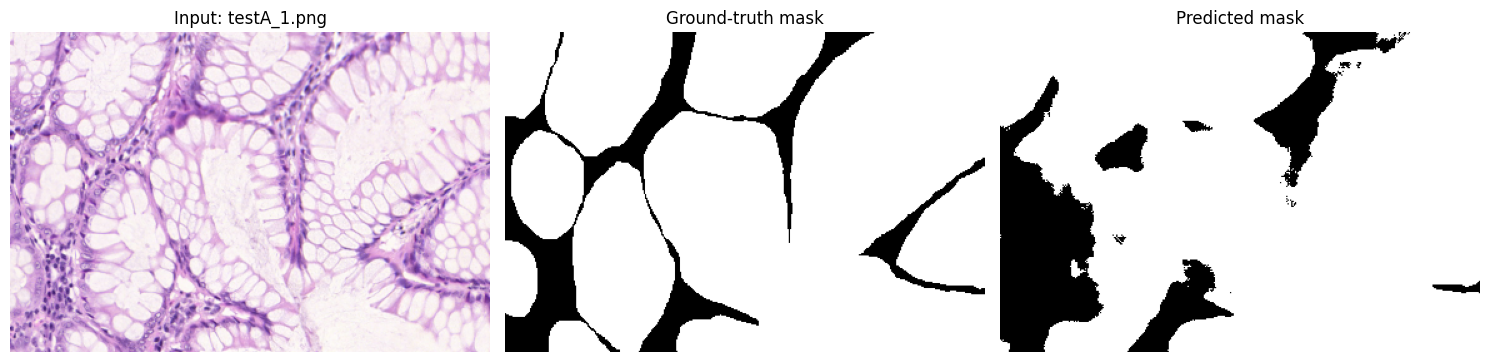


All outputs saved under: /raid/home/dgx1725/attention_unet_warwick_outputs


In [8]:
# ============================================================
# 8. VISUALIZE AND SAVE A SAMPLE PREDICTION
# ============================================================
def show_prediction(model, pair, save_path=None):
    image_path, mask_path = pair
    image, gt_mask = load_image_mask(image_path, mask_path)
    probability = model.predict(np.expand_dims(image, axis=0), verbose=0)[0, ..., 0]
    pred_mask = (probability >= PRED_THRESHOLD).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image)
    axes[0].set_title(f"Input: {Path(image_path).name}")
    axes[1].imshow(gt_mask.squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground-truth mask")
    axes[2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Predicted mask")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print("Saved prediction visualization:", save_path)
    plt.show()


# Display one validation sample for visual inspection and one test example optionally.
show_prediction(model, val_pairs[0], OUTPUT_DIR / "sample_validation_prediction.png")
# Uncomment if you also want to save a test example:
# show_prediction(model, test_pairs[0], OUTPUT_DIR / "sample_test_prediction.png")

print("\nAll outputs saved under:", OUTPUT_DIR)